In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
import figurefirst as fifi
from IPython.display import display,SVG
import os
import scipy.signal as signal
import scipy.fft
import copy
import fly_plot_lib.plot as fpl

In [2]:
pwd

'/Users/jaleesahoule/Desktop/SPLITFLOW/final_split_flow_gitrepo/SplitFlowOptoTracking_new/FigureGeneration/Supplemental/sup_fig_tunnel_methods'

In [ ]:
# Data from Dryad (wind_tunnel_data.zip) unzipped into Data/ at the repo root;
# the smoke images live with Figure 2.
WIND_DIR = '../../../Data/wind_tunnel_data'
SMOKE_DIR = '../../Main/fig_2_wind_tunnel_CFD/smokepen_images/'

# Loading all the 10 hz data collected in wind tunnel

* df_0 - df_100 is laminar data
* df_H_xx is the sensor in the horizontal split conditon
* df_V_xx is the sensor in the vertical split conditon
* xx name convention is by location in the wind tunnel data was collected

|    |    |    |
|----|----|----|
| RB | RC | RF |
| MB | MC | MF |
| LB | LC | LF |



In [ ]:
# load wind tunnel data
LAMINAR_DIR = os.path.join(WIND_DIR, 'laminar_flow')
SPLIT_DIR = os.path.join(WIND_DIR, '10_hz_splitflowdata')
df_0=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_0.csv'))
df_20=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_20.csv'))
df_40=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_40.csv'))
df_60=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_60.csv'))
df_80=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_80.csv'))
df_100=pd.read_csv(os.path.join(LAMINAR_DIR, 'laminar_100.csv'))
df_H_LB=pd.read_csv(os.path.join(SPLIT_DIR, 'H_LB.csv'))
df_H_LC=pd.read_csv(os.path.join(SPLIT_DIR, 'H_LC.csv'))
df_H_LF=pd.read_csv(os.path.join(SPLIT_DIR, 'H_LF.csv'))
df_H_MB=pd.read_csv(os.path.join(SPLIT_DIR, 'H_MB.csv'))
df_H_MC=pd.read_csv(os.path.join(SPLIT_DIR, 'H_MC.csv'))
df_H_MF=pd.read_csv(os.path.join(SPLIT_DIR, 'H_MF.csv'))
df_H_RB=pd.read_csv(os.path.join(SPLIT_DIR, 'H_RB.csv'))
df_H_RC=pd.read_csv(os.path.join(SPLIT_DIR, 'H_RC.csv'))
df_H_RF=pd.read_csv(os.path.join(SPLIT_DIR, 'H_RF.csv'))
df_V_LB=pd.read_csv(os.path.join(SPLIT_DIR, 'V_LB.csv'))
df_V_LC=pd.read_csv(os.path.join(SPLIT_DIR, 'V_LC.csv'))
df_V_LF=pd.read_csv(os.path.join(SPLIT_DIR, 'V_LF.csv'))
df_V_MB=pd.read_csv(os.path.join(SPLIT_DIR, 'V_MB.csv'))
df_V_MC=pd.read_csv(os.path.join(SPLIT_DIR, 'V_MC.csv'))
df_V_MF=pd.read_csv(os.path.join(SPLIT_DIR, 'V_MF.csv'))
df_V_RB=pd.read_csv(os.path.join(SPLIT_DIR, 'V_RB.csv'))
df_V_RC=pd.read_csv(os.path.join(SPLIT_DIR, 'V_RC.csv'))
df_V_RF=pd.read_csv(os.path.join(SPLIT_DIR, 'V_RF.csv'))

print(df_0.columns)

## Column titles should be 'time', 'xy_X', 'xy_Y', 'xz_X', 'xz_Z'

##### time is every 1/10th of a second

##### xy_X = X component of the wind with the senor in the xy orientation 

##### xy_Y = Y component of the wind with the senor in the xy orientation 

##### xz_X = X component of the wind with the senor in the xz orientation 

##### xz_Z = Z component of the wind with the senor in the xz orientation 

In [ ]:
# load outdoor data
df_TNF = pd.read_csv(os.path.join(WIND_DIR, 'outdoor_data', 'df_TNF.csv'))

# function that inputs speed and direction and gets out velocity components x y and tacks it on to the data frame
def wind_components_H(df):
    df['Vx_H'] = -1*df['S2_7'].values*np.cos(np.radians(df['D_7'].values))
    df['Vy_H'] = -1*df['S2_7'].values*np.sin(np.radians(df['D_7'].values))
    return df

def wind_components_V(df):
    df['Vx_V'] = -1*df['S2_8_verticallyorientated'].values*np.cos(np.radians(df['D_8_verticallyorientated'].values))
    df['Vy_V'] = -1*df['S2_8_verticallyorientated'].values*np.sin(np.radians(df['D_8_verticallyorientated'].values))
    return df

df_TNF = wind_components_H(df_TNF)
df_TNF = wind_components_V(df_TNF)

df_TNF.columns

In [170]:
print('Forest data is ' + str(len(df_TNF)/10.) + ' sec long' )

Forest data is 14942.6 sec long


In [171]:
14942.6/3600.

4.150722222222222

# Helper functions

In [172]:
def find_variance_intervals(df, column_low_var, column_high_var, interval_seconds, frequency):
    # Calculate the number of data points in one interval
    points_per_interval = int(interval_seconds / frequency)
    
    # Initialize variables to keep track of the best interval found
    best_interval_start = None
    best_interval_end = None
    min_variance = float('inf')
    max_variance = float('-inf')

    # Sliding window approach to check every n-second interval
    for start_idx in range(len(df) - points_per_interval + 1):
        end_idx = start_idx + points_per_interval
        
        # Get the current interval
        interval_df = df.iloc[start_idx:end_idx]
        
        # Calculate variances
        variance_low_var = interval_df[column_low_var].var()
        variance_high_var = interval_df[column_high_var].var()
        
        # Check if this interval meets the criteria
        if variance_low_var < min_variance and variance_high_var > max_variance:
            min_variance = variance_low_var
            max_variance = variance_high_var
            best_interval_start = start_idx
            best_interval_end = end_idx

    return best_interval_start, best_interval_end

In [173]:
def wrapped_angular_difference(a, b):
    return np.arctan2(np.sin(a-b), np.cos(a-b))

def wrap_angle(a):
    return np.arctan2(np.sin(a), np.cos(a))

def mean_angle(angle):
    return np.arctan2(np.nanmean(np.sin(angle)), np.nanmean(np.cos(angle)))

# Define high-pass filter
def high_pass_filter(data, cutoff, fs, order=5):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = signal.butter(order, normal_cutoff, btype='high', analog=False)
    y = signal.filtfilt(b, a, data)
    return y

def calc_filtered_angles(df_TNF, angle_key):

    lastframe = len(df_TNF)-1
    TNF_angdiff = wrapped_angular_difference(df_TNF[angle_key][1:lastframe+1].values, 
                                             df_TNF[angle_key][0:lastframe].values)
    
    fs = 10  # Sampling frequency (Hz), adjust as per your data
    time_constant = 30 # seconds
    cutoff = 1 / (2*time_constant)  # Cutoff frequency (1 / 30 seconds)

    TNF_angdiff_highpassed = high_pass_filter(TNF_angdiff, cutoff, fs)

    y = wrap_angle(np.cumsum(TNF_angdiff_highpassed) )

    y = wrap_angle(y - mean_angle(y))
    
    y = np.hstack([y[0], y])
    
    #return y
    df_TNF['filtered_' + angle_key] = y

In [174]:
# function to get the angle and magnitude from x and y velocity components inputs should be the data frame and the column names of the x and y velocity components save the angle and magnitude to the data frame
def angle_magnitude_XY(df, x, y):
    df['angle_XY'] = np.arctan2(df[y],df[x])
    df['magnitude_XY'] = np.sqrt(df[x]**2 + df[y]**2)
    calc_filtered_angles(df, 'angle_XY')
    return df

def angle_magnitude_XZ(df, x, y):
    df['angle_XZ'] = np.arctan2(df[y],df[x])
    df['magnitude_XZ'] = np.sqrt(df[x]**2 + df[y]**2)
    return df

# Calculate angles and magnitudes

In [175]:
# make xz_Z negative for df_H and df_V
df_H_LB['xz_Z'] = -1*df_H_LB['xz_Z']
df_H_LC['xz_Z'] = -1*df_H_LC['xz_Z']
df_H_LF['xz_Z'] = -1*df_H_LF['xz_Z']
df_H_MB['xz_Z'] = -1*df_H_MB['xz_Z']
df_H_MC['xz_Z'] = -1*df_H_MC['xz_Z']
df_H_MF['xz_Z'] = -1*df_H_MF['xz_Z']
df_H_RB['xz_Z'] = -1*df_H_RB['xz_Z']
df_H_RC['xz_Z'] = -1*df_H_RC['xz_Z']
df_H_RF['xz_Z'] = -1*df_H_RF['xz_Z']
df_V_LB['xz_Z'] = -1*df_V_LB['xz_Z']
df_V_LC['xz_Z'] = -1*df_V_LC['xz_Z']
df_V_LF['xz_Z'] = -1*df_V_LF['xz_Z']
df_V_MB['xz_Z'] = -1*df_V_MB['xz_Z']
df_V_MC['xz_Z'] = -1*df_V_MC['xz_Z']
df_V_MF['xz_Z'] = -1*df_V_MF['xz_Z']
df_V_RB['xz_Z'] = -1*df_V_RB['xz_Z']
df_V_RC['xz_Z'] = -1*df_V_RC['xz_Z']
df_V_RF['xz_Z'] = -1*df_V_RF['xz_Z']

In [176]:
# get the angle and magnitude of the horizontal velocity components and vertical velocity components
df_0 = angle_magnitude_XY(df_0, 'xy_X', 'xy_Y')
df_0 = angle_magnitude_XZ(df_0, 'xz_X', 'xz_Z')
df_20 = angle_magnitude_XY(df_20, 'xy_X', 'xy_Y')
df_20 = angle_magnitude_XZ(df_20, 'xz_X', 'xz_Z')
df_40 = angle_magnitude_XY(df_40, 'xy_X', 'xy_Y')
df_40 = angle_magnitude_XZ(df_40, 'xz_X', 'xz_Z')
df_60 = angle_magnitude_XY(df_60, 'xy_X', 'xy_Y')
df_60 = angle_magnitude_XZ(df_60, 'xz_X', 'xz_Z')
df_80 = angle_magnitude_XY(df_80, 'xy_X', 'xy_Y')
df_80 = angle_magnitude_XZ(df_80, 'xz_X', 'xz_Z')
df_100 = angle_magnitude_XY(df_100, 'xy_X', 'xy_Y')
df_100 = angle_magnitude_XZ(df_100, 'xz_X', 'xz_Z')
df_H_LB = angle_magnitude_XY(df_H_LB, 'xy_X', 'xy_Y')
df_H_LB = angle_magnitude_XZ(df_H_LB, 'xz_X', 'xz_Z')
df_H_LC = angle_magnitude_XY(df_H_LC, 'xy_X', 'xy_Y')
df_H_LC = angle_magnitude_XZ(df_H_LC, 'xz_X', 'xz_Z')
df_H_LF = angle_magnitude_XY(df_H_LF, 'xy_X', 'xy_Y')
df_H_LF = angle_magnitude_XZ(df_H_LF, 'xz_X', 'xz_Z')
df_H_MB = angle_magnitude_XY(df_H_MB, 'xy_X', 'xy_Y')
df_H_MB = angle_magnitude_XZ(df_H_MB, 'xz_X', 'xz_Z')
df_H_MC = angle_magnitude_XY(df_H_MC, 'xy_X', 'xy_Y')
df_H_MC = angle_magnitude_XZ(df_H_MC, 'xz_X', 'xz_Z')
df_H_MF = angle_magnitude_XY(df_H_MF, 'xy_X', 'xy_Y')
df_H_MF = angle_magnitude_XZ(df_H_MF, 'xz_X', 'xz_Z')
df_H_RB = angle_magnitude_XY(df_H_RB, 'xy_X', 'xy_Y')
df_H_RB = angle_magnitude_XZ(df_H_RB, 'xz_X', 'xz_Z')
df_H_RC = angle_magnitude_XY(df_H_RC, 'xy_X', 'xy_Y')
df_H_RC = angle_magnitude_XZ(df_H_RC, 'xz_X', 'xz_Z')
df_H_RF = angle_magnitude_XY(df_H_RF, 'xy_X', 'xy_Y')
df_H_RF = angle_magnitude_XZ(df_H_RF, 'xz_X', 'xz_Z')
df_V_LB = angle_magnitude_XY(df_V_LB, 'xy_X', 'xy_Y')
df_V_LB = angle_magnitude_XZ(df_V_LB, 'xz_X', 'xz_Z')
df_V_LC = angle_magnitude_XY(df_V_LC, 'xy_X', 'xy_Y')
df_V_LC = angle_magnitude_XZ(df_V_LC, 'xz_X', 'xz_Z')
df_V_LF = angle_magnitude_XY(df_V_LF, 'xy_X', 'xy_Y')
df_V_LF = angle_magnitude_XZ(df_V_LF, 'xz_X', 'xz_Z')
df_V_MB = angle_magnitude_XY(df_V_MB, 'xy_X', 'xy_Y')
df_V_MB = angle_magnitude_XZ(df_V_MB, 'xz_X', 'xz_Z')
df_V_MC = angle_magnitude_XY(df_V_MC, 'xy_X', 'xy_Y')
df_V_MC = angle_magnitude_XZ(df_V_MC, 'xz_X', 'xz_Z')
df_V_MF = angle_magnitude_XY(df_V_MF, 'xy_X', 'xy_Y')
df_V_MF = angle_magnitude_XZ(df_V_MF, 'xz_X', 'xz_Z')
df_V_RB = angle_magnitude_XY(df_V_RB, 'xy_X', 'xy_Y')
df_V_RB = angle_magnitude_XZ(df_V_RB, 'xz_X', 'xz_Z')
df_V_RC = angle_magnitude_XY(df_V_RC, 'xy_X', 'xy_Y')
df_V_RC = angle_magnitude_XZ(df_V_RC, 'xz_X', 'xz_Z')
df_V_RF = angle_magnitude_XY(df_V_RF, 'xy_X', 'xy_Y')
df_V_RF = angle_magnitude_XZ(df_V_RF, 'xz_X', 'xz_Z')
df_TNF = angle_magnitude_XY(df_TNF, 'Vx_H', 'Vy_H')
df_TNF = angle_magnitude_XZ(df_TNF, 'Vx_V', 'Vy_V')


In [177]:
df_TNF

,Unnamed: 0,TIME,S2_7,D_7,S2_8_verticallyorientated,D_8_verticallyorientated,Vx_H,Vy_H,Vx_V,Vy_V,angle_XY,magnitude_XY,filtered_angle_XY,angle_XZ,magnitude_XZ
0,0,0.0,0.72,67.0,0.24,259.0,-0.281326,-0.662763,0.045794,0.235591,-1.972222,0.72,-0.748394,1.378810,0.24
1,1,0.1,0.72,67.0,0.24,259.0,-0.281326,-0.662763,0.045794,0.235591,-1.972222,0.72,-0.748394,1.378810,0.24
2,2,0.2,0.60,53.0,0.57,286.0,-0.361089,-0.479181,-0.157113,0.547919,-2.216568,0.60,-1.153098,1.850049,0.57
3,3,0.3,0.94,73.0,0.17,196.0,-0.274829,-0.898926,0.163414,0.046858,-1.867502,0.94,-0.962838,0.279253,0.17
4,4,0.4,0.49,58.0,0.23,193.0,-0.259660,-0.415544,0.224105,0.051739,-2.129302,0.49,-1.381894,0.226893,0.23
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
149421,149421,14942.1,0.72,144.0,0.77,84.0,0.582492,-0.423205,-0.080487,-0.765782,-0.628319,0.72,2.188895,-1.675516,0.77
149422,149422,14942.2,0.82,144.0,0.73,94.0,0.663394,-0.481984,0.050922,-0.728222,-0.628319,0.82,2.154430,-1.500983,0.73
149423,149423,14942.3,0.71,145.0,0.86,96.0,0.581598,-0.407239,0.089894,-0.855289,-0.610865,0.71,2.134667,-1.466077,0.86
149424,149424,14942.4,0.81,148.0,0.76,96.0,0.686919,-0.429235,0.079442,-0.755837,-0.558505,0.81,2.147003,-1.466077,0.76


In [178]:
def get_fft_XY(df,window_size):
    if 'time' in df.columns:
        # Filter the DataFrame based on the 'TIME' column
        df1 = df[df['time'] < window_size]
        data=np.array(df1['magnitude_XY'])
        time = df1['time']
    # Filter the DataFrame based on the 'TIME' column
    else:
        df1 = df[df['TIME'] < window_size]
        data=np.array(df1['magnitude_XY'])
        time = df1['TIME']

    # Replace NaN values with the median of the data
    data = pd.Series(data).fillna(pd.Series(data).median()).to_numpy()

    # time = df['time']

    # Number of sample points
    N = len(time)

    # Sample spacing
    T = 1.0 /(len(time)/(time.iloc[-1]-time.iloc[0]))

    y = data
    yf = scipy.fft.fft(y)
    xf = np.linspace(0.0, 1.0/(2.0*T), N//2)

    # X = np.log10(xf[1:])
    X = xf[1:]
    # Y = np.log10(2.0/N * np.abs(yf[1:N//2]))
    Y = 2.0/N * np.abs(yf[1:N//2])
    # X and Y are smaller than the original data add NAN to the end of the data to make it the same size as the original data
    Xsize = len(df) - len(X)
    Ysize = len(df) - len(Y)
    X = np.append(X, np.zeros(Xsize)*np.nan)
    Y = np.append(Y, np.zeros(Ysize)*np.nan)

    df['XY_FFT_X'] = X
    df['XY_FFT_Y'] = Y

    return df

def get_fft_XZ(df,window_size):
    if 'time' in df.columns:
        # Filter the DataFrame based on the 'TIME' column
        df1 = df[df['time'] < window_size]
        data=np.array(df1['magnitude_XZ'])
        time = df1['time']
    # Filter the DataFrame based on the 'TIME' column
    else:
        df1 = df[df['TIME'] < window_size]
        data=np.array(df1['magnitude_XZ'])
        time = df1['TIME']

    # Replace NaN values with the median of the data
    data = pd.Series(data).fillna(pd.Series(data).median()).to_numpy()

    # time = df['time']

    # Number of sample points
    N = len(time)

    # Sample spacing
    T = 1.0 /(len(time)/(time.iloc[-1]-time.iloc[0]))

    y = data
    yf = scipy.fft.fft(y)
    xf = np.linspace(0.0, 1.0/(2.0*T), N//2)

    # X = np.log10(xf[1:])
    X = xf[1:]
    # Y = np.log10(2.0/N * np.abs(yf[1:N//2]))
    Y = 2.0/N * np.abs(yf[1:N//2])
    # X and Y are smaller than the original data add NAN to the end of the data to make it the same size as the original data
    Xsize = len(df) - len(X)
    Ysize = len(df) - len(Y)
    X = np.append(X, np.zeros(Xsize)*np.nan)
    Y = np.append(Y, np.zeros(Ysize)*np.nan)

    df['XZ_FFT_X'] = X
    df['XZ_FFT_Y'] = Y

    return df

# Calculate fft

In [179]:
print (len(df_0['magnitude_XY']))
print(df_0['time'].iloc[-1])

1797
179.60000000000002


In [180]:
# get fft for all the data
df_0    =get_fft_XY(df_0   ,150)
df_0    =get_fft_XZ(df_0   ,150)
df_20   =get_fft_XY(df_20  ,150)
df_20   =get_fft_XZ(df_20  ,150)
df_40   =get_fft_XY(df_40  ,150)
df_40   =get_fft_XZ(df_40  ,150)
df_60   =get_fft_XY(df_60  ,150)
df_60   =get_fft_XZ(df_60  ,150)
df_80   =get_fft_XY(df_80  ,150)
df_80   =get_fft_XZ(df_80  ,150)
df_100  =get_fft_XY(df_100 ,150)
df_100  =get_fft_XZ(df_100 ,150)
df_H_LB =get_fft_XY(df_H_LB,150)
df_H_LB =get_fft_XZ(df_H_LB,150)
df_H_LC =get_fft_XY(df_H_LC,150)
df_H_LC =get_fft_XZ(df_H_LC,150)
df_H_LF =get_fft_XY(df_H_LF,150)
df_H_LF =get_fft_XZ(df_H_LF,150)
df_H_MB =get_fft_XY(df_H_MB,150)
df_H_MB =get_fft_XZ(df_H_MB,150)
df_H_MC =get_fft_XY(df_H_MC,150)
df_H_MC =get_fft_XZ(df_H_MC,150)
df_H_MF =get_fft_XY(df_H_MF,150)
df_H_MF =get_fft_XZ(df_H_MF,150)
df_H_RB =get_fft_XY(df_H_RB,150)
df_H_RB =get_fft_XZ(df_H_RB,150)
df_H_RC =get_fft_XY(df_H_RC,150)
df_H_RC =get_fft_XZ(df_H_RC,150)
df_H_RF =get_fft_XY(df_H_RF,150)
df_H_RF =get_fft_XZ(df_H_RF,150)
df_V_LB =get_fft_XY(df_V_LB,150)
df_V_LB =get_fft_XZ(df_V_LB,150)
df_V_LC =get_fft_XY(df_V_LC,150)
df_V_LC =get_fft_XZ(df_V_LC,150)
df_V_LF =get_fft_XY(df_V_LF,150)
df_V_LF =get_fft_XZ(df_V_LF,150)
df_V_MB =get_fft_XY(df_V_MB,150)
df_V_MB =get_fft_XZ(df_V_MB,150)
df_V_MC =get_fft_XY(df_V_MC,150)
df_V_MC =get_fft_XZ(df_V_MC,150)
df_V_MF =get_fft_XY(df_V_MF,150)
df_V_MF =get_fft_XZ(df_V_MF,150)
df_V_RB =get_fft_XY(df_V_RB,150)
df_V_RB =get_fft_XZ(df_V_RB,150)
df_V_RC =get_fft_XY(df_V_RC,150)
df_V_RC =get_fft_XZ(df_V_RC,150)
df_V_RF =get_fft_XY(df_V_RF,150)
df_V_RF =get_fft_XZ(df_V_RF,150)
df_TNF  =get_fft_XY(df_TNF ,150)
df_TNF  =get_fft_XZ(df_TNF ,150) 


# getting TI and STDV

In [220]:
import pandas as pd
import numpy as np
from scipy.stats import circstd
import math

from numpy import (isscalar, r_, log, around, unique, asarray, zeros,
                   arange, sort, amin, amax, atleast_1d, sqrt, array,
                   compress, pi, exp, ravel, count_nonzero, sin, cos,
                   arctan2, hypot)


def _circfuncs_common(samples, high, low, nan_policy='propagate'):
    # Ensure samples are array-like and size is not zero
    samples = np.asarray(samples)
    if samples.size == 0:
        return np.nan, np.asarray(np.nan), np.asarray(np.nan), None

    # Recast samples as radians that range between 0 and 2 pi and calculate
    # the sine and cosine
    sin_samp = sin((samples - low)*2.*pi / (high - low))
    cos_samp = cos((samples - low)*2.*pi / (high - low))
    #sin_samp=sin(samples)
    #cos_samp=cos(samples)
    mask = None
    return samples, sin_samp, cos_samp, mask

def mycircstd(samples, high=360, low=0, axis=None, nan_policy='omit'):

    samples, sin_samp, cos_samp, mask = _circfuncs_common(samples, high, low,
                                                          nan_policy=nan_policy)
    if mask is None:
        sin_mean = sin_samp.mean(axis=axis)  # [1] (2.2.3)
        cos_mean = cos_samp.mean(axis=axis)  # [1] (2.2.3)
    else:
        nsum = np.asarray(np.sum(~mask, axis=axis).astype(float))
        nsum[nsum == 0] = np.nan
        sin_mean = sin_samp.sum(axis=axis) / nsum
        cos_mean = cos_samp.sum(axis=axis) / nsum
    # hypot can go slightly above 1 due to rounding errors
    with np.errstate(invalid='ignore'):
        R = np.minimum(1, hypot(sin_mean, cos_mean))  # [1] (2.2.4)
    res = np.sqrt(2 * (1 -R))
    
    return res*180/np.pi

# function that take in the data frame, and window size in seconds and returns TI for magnitude_XY and STDV of filtered_angle_XY in degrees
def get_TI_STDV(df, window_size,total_time):
    if 'time' in df.columns:
        # Filter the DataFrame based on the 'TIME' column
        df1 = df[df['time'] < total_time]
        TI_data=np.array(df1['magnitude_XY'])
        STDV_data=np.array(df1['angle_XY'])
        time = df1['time']
    # Filter the DataFrame based on the 'TIME' column
    else:
        df1 = df[df['TIME'] < total_time]
        TI_data=np.array(df1['magnitude_XY'])
        STDV_data=np.array(df1['filtered_angle_XY'])
        time = df1['TIME']

    # Replace NaN values with the median of the data
    # TI_data = pd.Series(TI_data).fillna(pd.Series(TI_data).median()).to_numpy()
    # STDV_data = pd.Series(STDV_data).fillna(pd.Series(STDV_data).median()).to_numpy()

    # chunck data into windows of size window_size
    # wind size is in seconds and sample rate is 10 Hz so should be chuncks of 10hz times window size
    num_windows = int(total_time/window_size)
    TI=[]
    STDV=[]
    for i in range(num_windows):
        start = i*window_size*10
        end = (i+1)*window_size*10
        
        TI.append(np.nanstd(TI_data[start:end])/np.nanmean(TI_data[start:end]))
        # np.degrees(mycircstd(np.degrees(STDV_data[start:end]), high=180, low=-180))

        # STDV.append(np.nanstd(STDV_data[start:end])*180/np.pi)
        STDV.append(mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360))

        # plt.plot(np.degrees(STDV_data[start:end]),color='black')
        # plt.plot(np.degrees(STDV_data[start:end]) + mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360)*3,color='red')
        # plt.plot(np.degrees(STDV_data[start:end]) - mycircstd(np.degrees(STDV_data[start:end]), high=360, low=-360)*3,color='red')
        # plt.title('Window ' + str(i)+ '\n Time: ' + str(time[start]) + ' to ' + str(time[end-1]) + '\n STDV: ' + str(mycircstd(np.degrees(STDV_data[start:end-1]), high=180, low=-180)))
        # plt.show()

    # add nan to the end of the data to make it the same size as the original data
    TIsize = len(df) - len(TI)
    STDVsize = len(df) - len(STDV)
    TI = np.append(TI, np.zeros(TIsize)*np.nan)
    STDV = np.append(STDV, np.zeros(STDVsize)*np.nan)

    df['TI'] = TI
    df['STDV'] = STDV

    return df
    

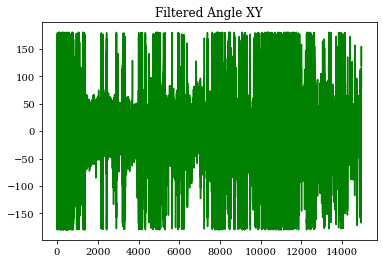

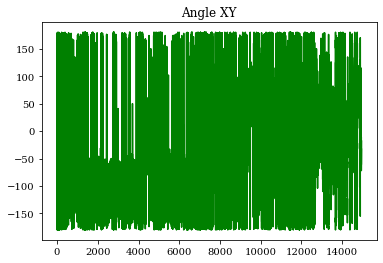

In [221]:
# plt.plot(df_H_RC['filtered_angle_XY'])
# plt.show()

# plt.plot(df_H_RC['filtered_angle_XY'][0:100])
# plt.show()

sub_data=df_TNF['filtered_angle_XY'].copy()

# for i in range(len(sub_data)):
#     if sub_data[i] < 2:
#         sub_data[i] = sub_data[i] + 2*np.pi

plt.plot(df_TNF['TIME'],np.degrees(sub_data),color='green')
plt.title('Filtered Angle XY')
plt.show()

plt.plot(df_TNF['TIME'],np.degrees(df_TNF['angle_XY']),color='green')
plt.title('Angle XY')
plt.show()

# plt.plot(df_H_RC['filtered_angle_XY'])
# plt.show()

In [222]:
df_H_RC    =get_TI_STDV(df_H_RC   ,5,150)

In [442]:
# get TI and STDV for all the data
df_0    =get_TI_STDV(df_0   ,5,150)
df_20   =get_TI_STDV(df_20  ,5,150)
df_40   =get_TI_STDV(df_40  ,5,150)
df_60   =get_TI_STDV(df_60  ,5,150)
df_80   =get_TI_STDV(df_80  ,5,150)
df_100  =get_TI_STDV(df_100 ,5,150)
df_H_LB =get_TI_STDV(df_H_LB,5,150)
df_H_LC =get_TI_STDV(df_H_LC,5,150)
df_H_LF =get_TI_STDV(df_H_LF,5,150)
df_H_MB =get_TI_STDV(df_H_MB,5,150)
df_H_MC =get_TI_STDV(df_H_MC,5,150)
df_H_MF =get_TI_STDV(df_H_MF,5,150)
df_H_RB =get_TI_STDV(df_H_RB,5,150)
df_H_RC =get_TI_STDV(df_H_RC,5,150)
df_H_RF =get_TI_STDV(df_H_RF,5,150)
df_V_LB =get_TI_STDV(df_V_LB,5,150)
df_V_LC =get_TI_STDV(df_V_LC,5,150)
df_V_LF =get_TI_STDV(df_V_LF,5,150)
df_V_MB =get_TI_STDV(df_V_MB,5,150)
df_V_MC =get_TI_STDV(df_V_MC,5,150)
df_V_MF =get_TI_STDV(df_V_MF,5,150)
df_V_RB =get_TI_STDV(df_V_RB,5,150)
df_V_RC =get_TI_STDV(df_V_RC,5,150)
df_V_RF =get_TI_STDV(df_V_RF,5,150)
df_TNF  =get_TI_STDV(df_TNF ,5,150)

In [443]:
df_H_RC['STDV']

0       2.050292
1       2.318142
2       2.581760
3       2.238252
4       2.091740
          ...   
1793         NaN
1794         NaN
1795         NaN
1796         NaN
1797         NaN
Name: STDV, Length: 1798, dtype: float64

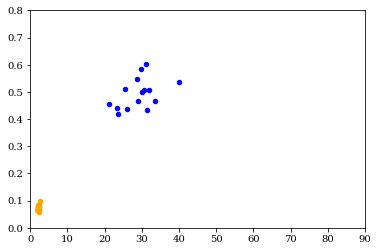

In [444]:
# plot standard deviation of filtered angle XY vs TI for df_TNF
plt.scatter(df_H_LC['STDV'], df_H_LC['TI'], s=20, color='blue')
# ax.scatter(df_H_MC['STDV'], df_H_MC['TI'], s=20, color=color_purple)
plt.scatter(df_H_RC['STDV'], df_H_RC['TI'], s=20, color='orange')
plt.xlim([0,90])
plt.ylim([0,.8])
plt.show()



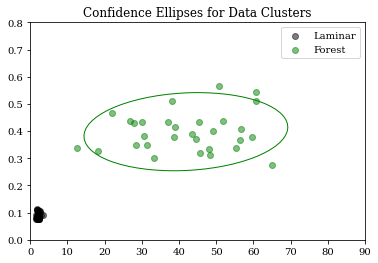

In [226]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def confidence_ellipse(x, y, ax, n_std=2.0, facecolor='none', **kwargs):
    """
    Create a plot of the covariance confidence ellipse of *x* and *y*.
    Parameters:
    - x, y: The data points.
    - ax: The axis on which to plot the ellipse.
    - n_std: The number of standard deviations to determine the ellipse's radii.
    - facecolor: The face color of the ellipse.
    - kwargs: Additional keyword arguments for the Ellipse patch.
    """
    if x.size != y.size:
        raise ValueError("x and y must be the same size")

    cov = np.cov(x, y)
    pearson = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2,
                      facecolor=facecolor, **kwargs)

    scale_x = np.sqrt(cov[0, 0]) * n_std
    scale_y = np.sqrt(cov[1, 1]) * n_std
    transf = (transforms.Affine2D()
              .rotate_deg(45)
              .scale(scale_x, scale_y)
              .translate(np.mean(x), np.mean(y)))

    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)

# Remove NaN values from the data
df_40_clean = df_40.dropna(subset=['STDV', 'TI'])
df_TNF_clean = df_TNF.dropna(subset=['STDV', 'TI'])

# Create the plot
fig, ax = plt.subplots()

# Scatter plots
ax.scatter(df_40_clean['STDV'], df_40_clean['TI'], color='black', alpha=0.5, label='Laminar')
ax.scatter(df_TNF_clean['STDV'], df_TNF_clean['TI'], color='green', alpha=0.5, label='Forest')

# Set limits
ax.set_xlim([0, 90])
ax.set_ylim([0, 0.8])

# Add confidence ellipses
confidence_ellipse(df_TNF_clean['STDV'], df_TNF_clean['TI'], ax, n_std=2, edgecolor='green')

# Add title and legend
ax.set_title('Confidence Ellipses for Data Clusters')
ax.legend()

# Show plot
plt.show()

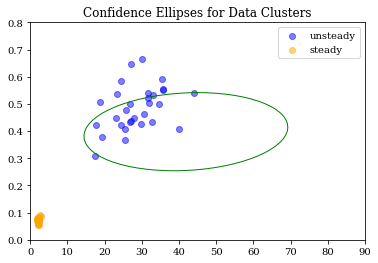

In [227]:
# Remove NaN values from the data
df_H_LC_clean = df_H_LC.dropna(subset=['STDV', 'TI'])
df_H_RC_clean = df_H_RC.dropna(subset=['STDV', 'TI'])

# Create the plot
fig, ax = plt.subplots()

# Scatter plots
ax.scatter(df_H_LC_clean['STDV'], df_H_LC_clean['TI'], color='blue', alpha=0.5, label='unsteady')
ax.scatter(df_H_RC_clean['STDV'], df_H_RC_clean['TI'], color='orange', alpha=0.5, label='steady')

# Set limits
ax.set_xlim([0, 90])
ax.set_ylim([0, 0.8])

# Add confidence ellipses
confidence_ellipse(df_TNF_clean['STDV'], df_TNF_clean['TI'], ax, n_std=2, edgecolor='green')

# Add title and legend
ax.set_title('Confidence Ellipses for Data Clusters')
ax.legend()

# Show plot
plt.show()

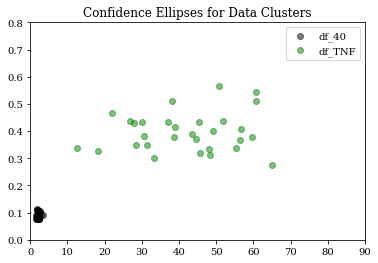

In [228]:
# Create the plot
fig, ax = plt.subplots()

# Scatter plots
ax.scatter(df_40['STDV'], df_40['TI'], color='black', alpha=0.5, label='df_40')
ax.scatter(df_TNF['STDV'], df_TNF['TI'], color='green', alpha=0.5, label='df_TNF')

# Set limits
ax.set_xlim([0, 90])
ax.set_ylim([0, 0.8])

# Add confidence ellipses
confidence_ellipse(df_40['STDV'], df_40['TI'], ax, n_std=2, edgecolor='black')
confidence_ellipse(df_TNF['STDV'], df_TNF['TI'], ax, n_std=2, edgecolor='green')

# Add title and legend
ax.set_title('Confidence Ellipses for Data Clusters')
ax.legend()

# Show plot
plt.show()

In [229]:
# # plot the fft of df_0
# plt.plot(df_0['XY_FFT_X'],df_0['XY_FFT_Y'])
# plt.show()

# plt.loglog(df_0['XY_FFT_X'],df_0['XY_FFT_Y'])
# plt.show()

# Colors

In [230]:
# creat a gradient of colors for the plot make them all shades of oragne
colors = plt.cm.Oranges(np.linspace(0, 1, 10))
# creat a gradient of colors for the plot make them all shades of purple
colors2 = plt.cm.Purples(np.linspace(0, 1, 10))
# creat a gradient of colors for the plot make them all shades of blue
colors3 = plt.cm.Blues(np.linspace(0, 1, 10))

color_black = 'black'
color_green = 'green'
color_orange = colors[6]
color_blue = colors3[6]
color_purple = colors2[6]

In [231]:
# print color code for blue purple and orange
print("color_blue = '" + str(color_blue) + "'")
print("color_purple = '" + str(color_purple) + "'")
print("color_orange = '" + str(color_orange) + "'")

color_blue = '[0.21568627 0.52941176 0.75424837 1.        ]'
color_purple = '[0.47320261 0.43267974 0.69934641 1.        ]'
color_orange = '[0.91372549 0.36862745 0.05098039 1.        ]'


In [ ]:
# Helvetica matches the published figure; log-axis tick labels use Computer Modern math text.
plt.rcParams['font.family'] = 'Helvetica'
plt.rcParams['text.usetex'] = False
plt.rcParams["ps.usedistiller"] = 'xpdf'
plt.rcParams['font.weight'] = 'normal'
plt.rcParams["mathtext.fontset"] = 'cm'

# start here

In [ ]:
# The supplemental tunnel-methods figure is built on tunnel_methods_supplement_template.svg
# (layout boxes + hand-made artwork and labels). This notebook runs first and starts a
# fresh copy of the template; CFD_plots.ipynb then adds the CFD panels (L-P).
# The committed, published version is output_figs/tunnel_methods_supplement.svg.
import shutil
TEMPLATE_SVG = 'tunnel_methods_supplement_template.svg'
input_svg = 'tunnel_methods_supplement.svg'
shutil.copy(TEMPLATE_SVG, input_svg)
layout = fifi.svg_to_axes.FigureLayout(input_svg, autogenlayers=True, make_mplfigures=True, hide_layers=[])

# Outdoorplots

In [695]:
# if 0: 
#     # Create a new figure
#     fig = plt.figure(figsize=(2,2))
#     # Add an axes to the figure, specifying it as a polar plot
#     ax = fig.add_axes([0.1, 0.1, 0.8, 0.8], polar=True)

# else:
#     ax = layout.axes[('outdoor', 'polar')]
    
# # Add an axes to the figure, specifying it as a polar plot

# first_frame = 0
# n_frames = len(df_TNF)

# TNF_angles = df_TNF['filtered_angle_XY'].values[first_frame:first_frame+n_frames]
# ax.scatter(TNF_angles - mean_angle(TNF_angles), 
#            df_TNF['magnitude_XY'].values[first_frame:first_frame+n_frames],s=.2, color=color_green, alpha=.1, edgecolor='none', zorder=-10)

# # ax.scatter(angles_LV, magnitudes_LV ,s=.5, color='orange', alpha=1)
# # ax.scatter(angles_TNF, magnitudes_TNF ,s=.5, color='green', alpha=1)
# # ax.scatter(angles_U, magnitudes_U ,s=.5, color='purple', alpha=1)
# # ax.scatter(angles_MH, magnitudes_MH, s=.5, color='yellow', alpha=.5)
# # ax.scatter(angles_ML, magnitudes_ML, s=.5, color='blue', alpha=.5)
# # ax.scatter(angles_MC, magnitudes_MC, s=.5, color='red', alpha=.5)
# # ax.scatter(angles, magnitudes ,s=.1, color='black', alpha=.5)

# #Set the x-ticks and labels
# # ax.set_xticks([0, np.pi/4, np.pi/2, 3*np.pi/2, np.pi , -3*np.pi/2, -np.pi/2, -np.pi/4])
# ax.set_xticklabels([])#'0', '$-\pi/4$', '$-\pi/2$', '$-3\pi/4$', '$\pm\pi$', '$3\pi/4$', '$\pi/2$', '$\pi/4$'])


# # Set the yticks off
# ax.set_yticks([0, 0.75, 1.5])
# ax.set_ylim([0,1.5])
# ax.set_yticklabels([])

# # Set the direction of the plot to clockwise
# ax.set_rlabel_position(180)
# ax.set_theta_direction(-1)

# # Set the zero to the top
# ax.set_theta_offset(0)

# ax.set_rasterization_zorder(0)

# if 0:
#     plt.show()
#     fig.savefig('polar_forest.pdf', dpi=300)

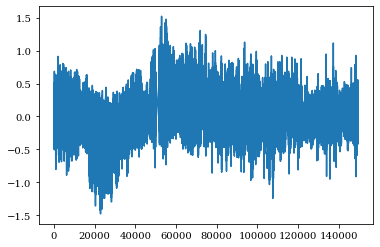

In [696]:
plt.plot(df_TNF['Vx_V'].values)

In [697]:
# if 0:
#     fig = plt.figure(figsize=(2,2))
#     ax = fig.add_axes([0.4, 0.1, 0.5, 0.8])
# else:
#     ax = layout.axes[('outdoor', 'vertical')]

# bins = np.linspace(-2,2,200)

# h, b = np.histogram(copy.copy(df_TNF['Vx_V'].values[first_frame:first_frame+n_frames]), bins)
# fpl.scatter_box_violin_distribution(ax, 1, copy.copy(df_TNF['Vx_V'].values[first_frame:first_frame+n_frames]), 
#                                     h, b, color=color_green, shading=None, linewidth=0,
#                                     markersize=1)

# ax.set_ylabel('Vertical wind velocity, m/s')

# ax.set_ylim(-1,1)
# fifi.mpl_functions.adjust_spines(ax, ['left'])
# fifi.mpl_functions.set_fontsize(ax, 6)

# ax.set_rasterization_zorder(0)

# if 0:
#     fig.savefig('vertical_outdoor.pdf', dpi=300)

In [ ]:
# layout.append_figure_to_layer(layout.figures['outdoor'], 'outdoor', cleartarget=True)
# layout.write_svg(input_svg)
#

# Laminar and outdoor snippet Polar plots

In [755]:
first_frame = 50000
n_frames = 1800
df_TNF['filtered_angle_XY'].values[first_frame:first_frame+n_frames]

array([ 0.14184622, -0.20474918, -0.27192587, ..., -0.12491253,
        0.50530147,  0.31523542])

In [756]:
if 0: 
    # Create a new figure
    fig = plt.figure(figsize=(2,2))
    # Add an axes to the figure, specifying it as a polar plot
    ax = fig.add_axes([0.1, 0.1, 0.8, 0.8], polar=True)

else:
    ax = layout.axes[('laminar', 'polar')]
    
# Add an axes to the figure, specifying it as a polar plot

first_frame = 50000
n_frames = 1800

TNF_angles = df_TNF['filtered_angle_XY'].values[first_frame:first_frame+n_frames]
ax.scatter(TNF_angles - mean_angle(TNF_angles), 
           df_TNF['magnitude_XY'].values[first_frame:first_frame+n_frames],s=.4, color=color_green, alpha=1, edgecolor='none', zorder=-10)

ax.scatter(df_40['angle_XY']-mean_angle(df_40['angle_XY']), 
           df_40['magnitude_XY'],s=.4, color=color_black, alpha=1, edgecolor='none', zorder=-1)


# ax.scatter(angles_LV, magnitudes_LV ,s=.5, color='orange', alpha=1)
# ax.scatter(angles_TNF, magnitudes_TNF ,s=.5, color='green', alpha=1)
# ax.scatter(angles_U, magnitudes_U ,s=.5, color='purple', alpha=1)
# ax.scatter(angles_MH, magnitudes_MH, s=.5, color='yellow', alpha=.5)
# ax.scatter(angles_ML, magnitudes_ML, s=.5, color='blue', alpha=.5)
# ax.scatter(angles_MC, magnitudes_MC, s=.5, color='red', alpha=.5)
# ax.scatter(angles, magnitudes ,s=.1, color='black', alpha=.5)

#Set the x-ticks and labels
# ax.set_xticks([0, np.pi/4, np.pi/2, 3*np.pi/2, np.pi , -3*np.pi/2, -np.pi/2, -np.pi/4])
ax.set_xticklabels([])#'0', '$-\pi/4$', '$-\pi/2$', '$-3\pi/4$', '$\pm\pi$', '$3\pi/4$', '$\pi/2$', '$\pi/4$'])


# Set the yticks off
ax.set_yticks([0, 0.75, 1.5])
ax.set_ylim([0,1.5])
ax.set_yticklabels([])

# Set the direction of the plot to clockwise
ax.set_rlabel_position(180)
ax.set_theta_direction(-1)

# Set the zero to the top
ax.set_theta_offset(0)

ax.set_rasterization_zorder(0)

if 0:
    plt.show()
    fig.savefig('polar_forest.pdf', dpi=300)

In [757]:
df_TNF['Vx_V'][first_frame:first_frame+n_frames]

50000   -0.464673
50001   -0.430668
50002   -0.385892
50003   -0.376222
50004   -0.362541
           ...   
51795    1.013252
51796    1.018100
51797    1.018475
51798    1.078324
51799    1.079242
Name: Vx_V, Length: 1800, dtype: float64

# Violin plots

In [ ]:
if 0:
    fig = plt.figure(figsize=(2,2))
    ax = fig.add_axes([0.4, 0.1, 0.5, 0.8])
else:
    ax = layout.axes[('laminar', 'vertical')]



bins = np.linspace(-2,2,200)
print("first_frame:", first_frame)
print("n_frames:", n_frames)
print("df_TNF['Vx_V'] values:", df_TNF['Vx_V'].values[first_frame:first_frame+n_frames])
print("df_40['xz_Z'] values:", df_40['xz_Z'].values)

h, b = np.histogram(df_TNF['Vx_V'].values[first_frame:first_frame+n_frames], bins)
fpl.scatter_box_violin_distribution(ax, 2, df_TNF['Vx_V'].values[first_frame:first_frame+n_frames], 
                                    h, b, color=color_green, shading=None, linewidth=0,
                                    markersize=1)

h, b = np.histogram(df_40['xz_Z'].values, bins)
fpl.scatter_box_violin_distribution(ax, 1, df_40['xz_Z'].values, 
                                    h, b, color=color_black, shading=None, linewidth=0,
                                    markersize=1)


#ax.set_ylabel('Vertical vel, m/s')

ax.set_ylim(-1,1)
ax.set_yticklabels([])
# fifi.mpl_functions.adjust_spines(ax, ['left'])
fifi.mpl_functions.adjust_spines(ax, ['left'], yticks =[-1,-.5,0,.5,1], spine_locations={'left': 2}, tick_length=3, linewidth=1)
ax.set_yticklabels([-1,-.5,0,.5,1])
# y label is text in the template
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_rasterization_zorder(0)

if 0:
    fig.savefig('vertical_outdoor.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['laminar'], 'laminar', cleartarget=True)
layout.write_svg(input_svg)

# steady and unsteady Polar plots

In [760]:
if 0:
    # Create a new figure
    fig = plt.figure(figsize=(2,2))

    # Add an axes to the figure, specifying it as a polar plot
    ax = fig.add_axes([0.1, 0.1, 0.8, 0.8], polar=True)
else:
    ax = layout.axes[('horizontal', 'polar')]
    
    
#ax.scatter(df_TNF['filtered_angle_XY'].values[0:], 
#           df_TNF['magnitude_XY'].values[0:],s=.2, color='green', alpha=0.1, edgecolor='none', zorder=-10)
ax.scatter(df_H_RC['angle_XY'], df_H_RC['magnitude_XY'],s=.4, edgecolor='none', color=color_orange, alpha=1, zorder=-1)
# ax.scatter(df_H_MC['angle_XY'], df_H_MC['magnitude_XY'],s=.4, edgecolor='none', color=color_purple, alpha=1, zorder=-1)
ax.scatter(df_H_LC['angle_XY'], df_H_LC['magnitude_XY'],s=.4, edgecolor='none', color=color_blue, alpha=1, zorder=-1)

#ax.scatter(df_40['angle_XY']-mean_angle(df_40['angle_XY']), 
#           df_40['magnitude_XY'],s=.5, color='black', alpha=1, zorder=-1)


# ax.scatter(angles_LV, magnitudes_LV ,s=.5, color='orange', alpha=1)
# ax.scatter(angles_TNF, magnitudes_TNF ,s=.5, color='green', alpha=1)
# ax.scatter(angles_U, magnitudes_U ,s=.5, color='purple', alpha=1)
# ax.scatter(angles_MH, magnitudes_MH, s=.5, color='yellow', alpha=.5)
# ax.scatter(angles_ML, magnitudes_ML, s=.5, color='blue', alpha=.5)
# ax.scatter(angles_MC, magnitudes_MC, s=.5, color='red', alpha=.5)
# ax.scatter(angles, magnitudes ,s=.1, color='black', alpha=.5)

#Set the x-ticks and labels
# ax.set_xticks([0, np.pi/4, np.pi/2, 3*np.pi/2, np.pi , -3*np.pi/2, -np.pi/2, -np.pi/4])
ax.set_xticklabels([])#'0', '$-\pi/4$', '$-\pi/2$', '$-3\pi/4$', '$\pm\pi$', '$3\pi/4$', '$\pi/2$', '$\pi/4$'])


# Set the yticks off
ax.set_yticks([0, 0.75, 1.5])
ax.set_ylim([0,1.5])
ax.set_yticklabels([])

# Set the direction of the plot to clockwise
ax.set_rlabel_position(180)
ax.set_theta_direction(-1)

# Set the zero to the top
ax.set_theta_offset(0)
    
ax.set_rasterization_zorder(0)

if 0:
    plt.show()
    fig.savefig('polar_forest.pdf', dpi=300)

# steady and unsteady Violin plots

In [ ]:
if 0:
    fig = plt.figure(figsize=(2,2))
    ax = fig.add_axes([0.4, 0.1, 0.5, 0.8])
else:
    ax = layout.axes[('horizontal', 'vertical')]
    
bins = np.linspace(-2,2,200)

#h, b = np.histogram(df_TNF['Vx_V'].values, bins)
#fpl.scatter_box_violin_distribution(ax, 1, df_TNF['Vx_V'].values, 
#                                    h, b, color='green', shading=None, linewidth=0,
#                                    markersize=0.1)

#h, b = np.histogram(df_40['xz_Z'].values, bins)
#fpl.scatter_box_violin_distribution(ax, 2, df_40['xz_Z'].values, 
#                                    h, b, color='black', shading=None, linewidth=0,
#                                    markersize=1)

h, b = np.histogram(df_H_RC['xz_Z'].values, bins)
fpl.scatter_box_violin_distribution(ax, 3, df_H_RC['xz_Z'].values, 
                                    h, b, color=color_orange, shading=None, linewidth=0,
                                    markersize=1)

# h, b = np.histogram(df_H_MC['xz_Z'].values, bins)
# fpl.scatter_box_violin_distribution(ax, 4, df_H_MC['xz_Z'].values, 
#                                     h, b, color=color_purple, shading=None, linewidth=0,
#                                     markersize=1)

h, b = np.histogram(df_H_LC['xz_Z'].values, bins)
fpl.scatter_box_violin_distribution(ax, 5, df_H_LC['xz_Z'].values, 
                                    h, b, color=color_blue, shading=None, linewidth=0,
                                    markersize=1)

#ax.set_ylabel('Vertical vel, m/s')

ax.set_ylim(-1,1)
ax.set_yticklabels([])
# fifi.mpl_functions.adjust_spines(ax, ['left'])
fifi.mpl_functions.adjust_spines(ax, ['left'], yticks =[-1,-.5,0,.5,1], spine_locations={'left': 2}, tick_length=3, linewidth=1)
ax.set_yticklabels([-1,-.5,0,.5,1])
# y label is text in the template
fifi.mpl_functions.set_fontsize(ax, 6)

ax.set_rasterization_zorder(0)

if 0:
    plt.show()
    fig.savefig('polar_forest.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['horizontal'], 'horizontal', cleartarget=True)
layout.write_svg(input_svg)

In [763]:
print(df_40.columns)
print(df_TNF.columns)

Index(['Unnamed: 0', 'time', 'xy_X', 'xy_Y', 'xz_X', 'xz_Z', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')
Index(['Unnamed: 0', 'TIME', 'S2_7', 'D_7', 'S2_8_verticallyorientated',
       'D_8_verticallyorientated', 'Vx_H', 'Vy_H', 'Vx_V', 'Vy_V', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')


# All Time series plots

In [765]:
print(df_H_RC.columns)

Index(['Unnamed: 0', 'time', 'xy_X', 'xy_Y', 'xz_X', 'xz_Z', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')


In [712]:
df_TNF.columns

Index(['Unnamed: 0', 'TIME', 'S2_7', 'D_7', 'S2_8_verticallyorientated',
       'D_8_verticallyorientated', 'Vx_H', 'Vy_H', 'Vx_V', 'Vy_V', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')

# All FFT plots

In [ ]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fft', 'A')]

ax.loglog(df_TNF['XY_FFT_X'], df_TNF['XY_FFT_Y'], linewidth=1, label='xy speed',color=color_green,alpha=.9)
ax.loglog(df_40['XY_FFT_X'], df_40['XY_FFT_Y'], linewidth=1, label='xy speed',color='black',alpha=.9)


############
ax.set_xlim([10**-2, 10**1])
ax.set_ylim([10**-8, 10**-1])
fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks =[10**-8, 10**-1], xticks=[10**-2, 10**1],
                                tick_length=3,spine_locations={'left': 5, 'bottom': 5}, linewidth=1)

# axis labels are text in the template
fifi.mpl_functions.set_fontsize(ax, 6)
############
# ax.set_rasterization_zorder(0)

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('fft', 'B')]

ax.loglog(df_H_LC['XY_FFT_X'], df_H_LC['XY_FFT_Y'], linewidth=1, color=color_blue, alpha=.75, zorder=-1)

# ax.loglog(df_H_MC['XY_FFT_X'], df_H_MC['XY_FFT_Y'], color=color_purple, alpha=.75, zorder=-1)

ax.loglog(df_H_RC['XY_FFT_X'], df_H_RC['XY_FFT_Y'], linewidth=1, color=color_orange, alpha=.75, zorder=-1)

############
ax.set_xlim([10**-2, 10**1])
ax.set_ylim([10**-8, 10**-1])
fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks =[10**-8, 10**-1], xticks=[10**-2, 10**1],
                                tick_length=3,spine_locations={'left': 5, 'bottom': 5}, linewidth=1)
# ax.set_xticklabels([])
# axis labels are text in the template
fifi.mpl_functions.set_fontsize(ax, 6)
############
# ax.set_rasterization_zorder(0)

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [771]:
# FLAG=0
# if FLAG:
#     # Create a new figure
#     fig = plt.figure(figsize=(2, 2))

#     # Add an axes to the figure
#     ax = fig.add_subplot(111)
# else:
#     ax = layout.axes[('fft', 'C')]

# ax.loglog(df_H_LC['XZ_FFT_X'], df_H_LC['XZ_FFT_Y'], color=color_blue, alpha=.75, zorder=-1)

# # ax.loglog(df_H_MC['XZ_FFT_X'], df_H_MC['XZ_FFT_Y'], color=color_purple, alpha=.75, zorder=-1)

# ax.loglog(df_H_RC['XZ_FFT_X'], df_H_RC['XZ_FFT_Y'], color=color_orange, alpha=.75, zorder=-1)

# ############
# ax.set_xlim([10**-2, 10**1])
# ax.set_ylim([10**-8, 10**-1])
# fifi.mpl_functions.adjust_spines(ax, ['left', 'bottom'], yticks =[10**-8, 10**-1], xticks=[10**-2, 10**1],
#                                 tick_length=3,spine_locations={'left': 0, 'bottom': 0}, linewidth=1)
# ax.set_ylabel('XZ',labelpad=-10)
# ax.set_xlabel('Frequency (Hz)',labelpad=-1)
# fifi.mpl_functions.set_fontsize(ax, 6)
# ############
# ax.set_rasterization_zorder(0)

# if FLAG:
#     plt.show()
#     # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['fft'], 'fft', cleartarget=True)
layout.write_svg(input_svg)

# All STDV and TI

# Steady smoke pics

In [ ]:
# import images from still_images/
# save all images in directory still_images/ to a dictionary
import os
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# path to the directory containing the images
path = SMOKE_DIR
# create an empty dictionary to store the images
images = {}
# loop through all the files in the directory
for filename in os.listdir(path):
    # check if the file is an image
    if filename.endswith('.jpg'):
        # read the image and store it in the dictionary
        images[filename] = mpimg.imread(os.path.join(path, filename))
# print the keys of the dictionary alpphabetically
print(sorted(images.keys()))
# print pixel dimensions of the first image x and y 
print('image x dimension:', images['steady_left_02_cal_rot_t=5.6s.jpg'].shape[0])

# display image and display fliped up image
# plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
# plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])

# 6 by 2 grid of images
# fig, axs = plt.subplots(6, 2, figsize=(2, 16))
# list of images to display
images_to_display = ['steady_left_02_cal_rot_t=5.6s.jpg', 'steady_bottom_01_cal_rot_t=12s.jpg',
                      'unsteady_right_04_cal_rot_t=45s.jpg', 'unsteady_bottom_01_cal_t=2.4s.jpg',
                        'steady_left_02_cal_rot_t=10.6s.jpg', 'unsteady_right_04_cal_rot_t=50s.jpg',
                          'unsteady_bottom_01_cal_t=7.8s.jpg', 'unsteady_right_04_cal_rot_t=40s.jpg',
                            'steady_bottom_01_cal_rot_t=2s.jpg', 'unsteady_bottom_01_cal_t=12.8s.jpg',
                              'steady_left_02_cal_rot_t=15.6s.jpg', 'steady_bottom_01_cal_rot_t=7s.jpg']
# loop through the images and display them
# for i, ax in enumerate(axs.flat):
#     ax.imshow(images[images_to_display[i]])
#     ax.axis('off')
#     # ax.set_xlim(700, 1200)
#     ax.set_ylim(700,1500)
# adjust the layout
# plt.subplots_adjust(wspace=0, hspace=0)
# save the figure
# plt.savefig('still_images/all_images.jpg', dpi=300, bbox_inches='tight')
# display the figure
# plt.show()

In [777]:
# print dimention of the first image
print(images['steady_left_02_cal_rot_t=5.6s.jpg'].shape)

(1920, 1200, 3)


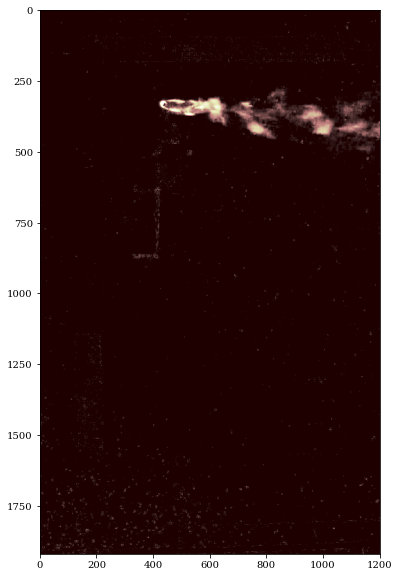

In [778]:
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'images' is a dictionary containing your images
image = images['steady_left_02_cal_rot_t=5.6s.jpg']

# Convert the RGB image to grayscale
gray_image = np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

# Flip the grayscale image vertically
flipped_image = np.flip(gray_image, axis=0)

# Create a new figure and axis
fig, ax = plt.subplots(figsize=(10, 10))  # Adjust the figsize as needed

# Plot the flipped grayscale image using cmap 'pink'
ax.imshow(flipped_image, cmap='pink', aspect='auto')

# Set the x and y limits
ax.set_xlim([0, 1200])
ax.set_ylim([1920, 0])  # Inverted y-axis

# Set the aspect ratio to be equal
ax.set_aspect('equal')

plt.show()

In [779]:
# function to grayscale an inputed image
def grayscale_image(image):
    return np.dot(image[..., :3], [0.2989, 0.5870, 0.1140])

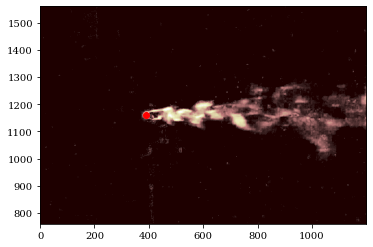

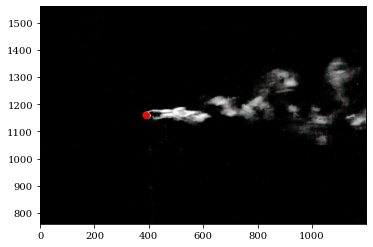

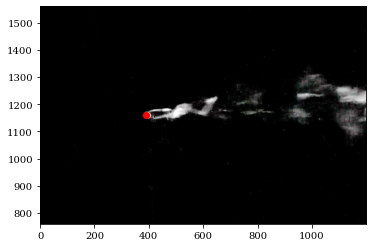

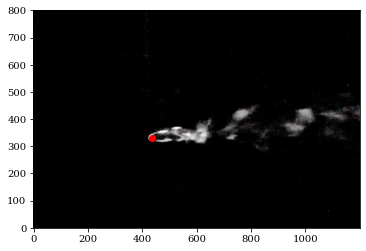

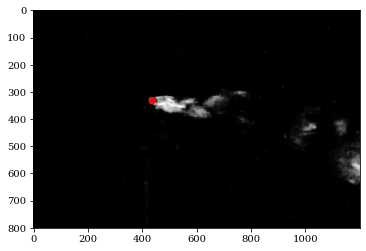

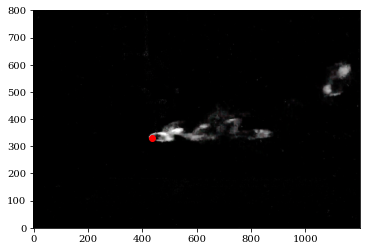

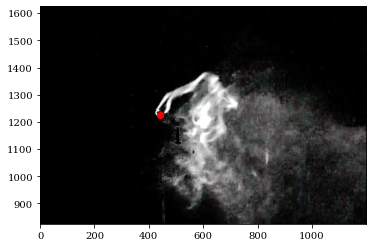

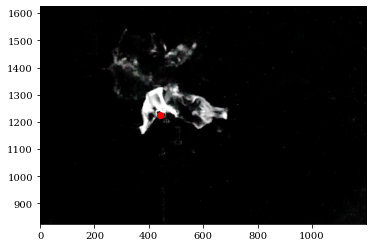

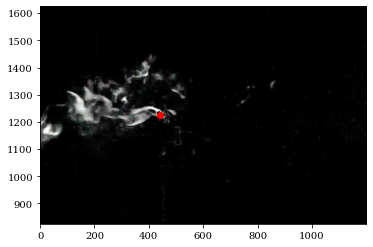

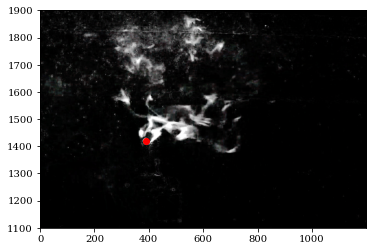

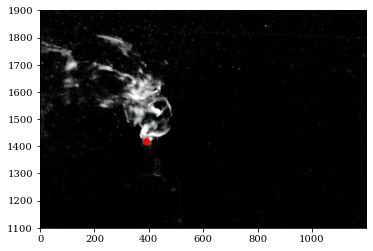

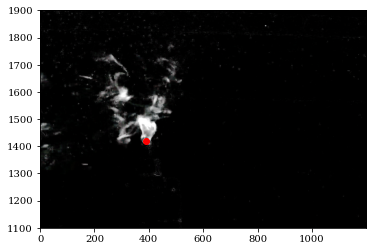

In [780]:
# plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
# plt.show()
# plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])
# plt.show()
# plot all images individually and have y limit
plt.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=2s.jpg']),cmap='pink')
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_bottom_01_cal_rot_t=7s.jpg'])
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_bottom_01_cal_rot_t=12s.jpg'])
plt.ylim(760,1560)
plt.scatter([390], [1160], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1])
plt.ylim(0,800)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=10.6s.jpg'][::-1])
plt.ylim(800,0)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['steady_left_02_cal_rot_t=15.6s.jpg'][::-1])
plt.ylim(0,800)
plt.scatter([435], [330], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=2.4s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=7.8s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_bottom_01_cal_t=12.8s.jpg'])
plt.ylim(825,1625)
plt.scatter([440], [1225], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=40s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=45s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()
plt.imshow(images['unsteady_right_04_cal_rot_t=50s.jpg'][::-1])
plt.ylim(1100,1900)
plt.scatter([390], [1420], color='red')
plt.show()


In [788]:
# print the keys in the dictionary
print(images.keys())

dict_keys(['steady_left_02_cal_rot_t=5.6s.jpg', 'steady_bottom_01_cal_rot_t=12s.jpg', 'unsteady_right_04_cal_rot_t=45s.jpg', 'unsteady_bottom_01_cal_t=2.4s.jpg', 'steady_left_02_cal_rot_t=10.6s.jpg', 'unsteady_right_04_cal_rot_t=50s.jpg', 'unsteady_bottom_01_cal_t=7.8s.jpg', 'unsteady_right_04_cal_rot_t=40s.jpg', 'steady_bottom_01_cal_rot_t=2s.jpg', 'unsteady_bottom_01_cal_t=12.8s.jpg', 'steady_left_02_cal_rot_t=15.6s.jpg', 'steady_bottom_01_cal_rot_t=7s.jpg'])


# Unsteady smoke pictures

# Steady_zoom pics

In [796]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'A')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=2s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1560,760])
#add red dot at x=390, y=1160
ax.scatter([390], [1160], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [797]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'B')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=7s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1560,760])
#add red dot at x=390, y=1160
ax.scatter([390], [1160], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [798]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'C')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['steady_bottom_01_cal_rot_t=12s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1560,760])
#add red dot at x=390, y=1160
ax.scatter([390], [1160], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [799]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'D')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink flip image vertically
ax.imshow(grayscale_image(images['steady_left_02_cal_rot_t=5.6s.jpg'][::-1]), cmap='pink', aspect='auto')
# ax.imshow(images['steady_bottom_01_cal_rot_t=2s.jpg'], cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([800,0])
#add red dot at x=435, y=330
ax.scatter([435], [330], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [800]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'E')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink flip image vertically
ax.imshow(grayscale_image(images['steady_left_02_cal_rot_t=10.6s.jpg'][::-1]), cmap='pink', aspect='auto')
# ax.imshow(images['steady_bottom_01_cal_rot_t=2s.jpg'], cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([800,0])
#add red dot at x=435, y=330
ax.scatter([435], [330], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [801]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('stead_smoke_zoom', 'F')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink flip image vertically
ax.imshow(grayscale_image(images['steady_left_02_cal_rot_t=15.6s.jpg'][::-1]), cmap='pink', aspect='auto')
# ax.imshow(images['steady_bottom_01_cal_rot_t=2s.jpg'], cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([800,0])
#add red dot at x=435, y=330
ax.scatter([435], [330], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['stead_smoke_zoom'], 'stead_smoke_zoom', cleartarget=True)
layout.write_svg(input_svg)

# Unsteady_Zoom pics

In [803]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'A')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_bottom_01_cal_t=2.4s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1625,825])
#add red dot at (440,1225)
ax.scatter([440], [1225], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [804]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'B')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_bottom_01_cal_t=7.8s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1625,825])
#add red dot at (440,1225)
ax.scatter([440], [1225], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [805]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'C')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_bottom_01_cal_t=12.8s.jpg']), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1625,825])
#add red dot at (440,1225)
ax.scatter([440], [1225], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [806]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'D')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_right_04_cal_rot_t=40s.jpg'][::-1]), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1900,1100])
# add red dot at x=390, y=1420
ax.scatter([390], [1420], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [807]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'E')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_right_04_cal_rot_t=45s.jpg'][::-1]), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1900,1100])
# add red dot at x=390, y=1420
ax.scatter([390], [1420], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [808]:
FLAG=0
if FLAG:
    # Create a new figure
    fig = plt.figure(figsize=(2, 2))

    # Add an axes to the figure
    ax = fig.add_subplot(111)
else:
    ax = layout.axes[('unstead_smoke_zoom', 'F')]

# plot steady_bottom_01_cal_rot_t=12s.jpg use cmap pink
ax.imshow(grayscale_image(images['unsteady_right_04_cal_rot_t=50s.jpg'][::-1]), cmap='pink', aspect='auto')
ax.set_xlim([0, 1200])
ax.set_ylim([1900,1100])
# add red dot at x=390, y=1420
ax.scatter([390], [1420], color='red',s=5)
ax.set_aspect('equal')
############

fifi.mpl_functions.adjust_spines(ax, [])

fifi.mpl_functions.set_fontsize(ax, 6)
###########

if FLAG:
    plt.show()
    # fig.savefig('indoor_wind_speed_split.pdf', dpi=300)

In [ ]:
layout.append_figure_to_layer(layout.figures['unstead_smoke_zoom'], 'unstead_smoke_zoom', cleartarget=True)
layout.write_svg(input_svg)

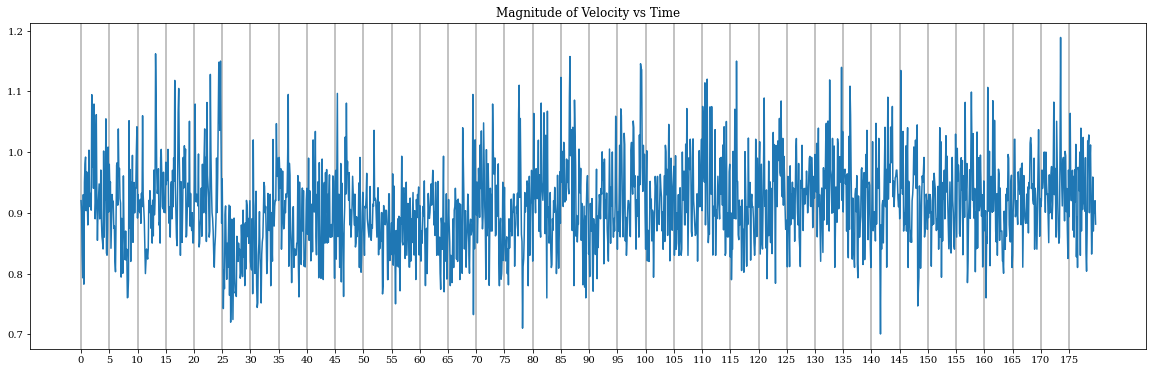

142.14968555982864
-143.9118092344257
143.0307473971272


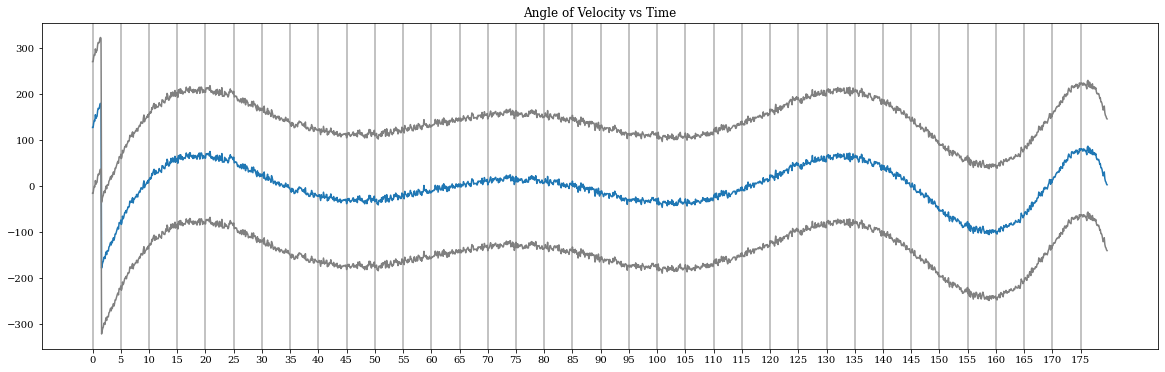

In [70]:
# Create a new figure with a larger size
plt.figure(figsize=(20, 6))  # Width: 20 inches, Height: 6 inches

# Plot the df_H_RC magnitude_XY vs time for the first 150 seconds
plt.plot(df_H_RC['time'], df_H_RC['magnitude_XY'])

# Set the x-ticks to be every 5 units
plt.xticks(range(0, int(df_H_RC['time'].max()) + 1, 5))

# Add grid lines every 5 units with increased alpha and thickness
plt.grid(which='major', axis='x', linestyle='-', alpha=1, linewidth=1.5)

#add title

plt.title('Magnitude of Velocity vs Time')

plt.show()

# Create a new figure with a larger size
plt.figure(figsize=(20, 6))  # Width: 20 inches, Height: 6 inches

# plot the angle_XY vs time for df_H_RC
plt.plot(df_H_RC['time'], df_H_RC['filtered_angle_XY']*180/np.pi)

# plot plus or minus 3 sigma
sigma_plus = (df_H_RC['filtered_angle_XY'].mean() + 3 * df_H_RC['filtered_angle_XY'].std())*180/np.pi
sigma_minus = (df_H_RC['filtered_angle_XY'].mean() - 3 * df_H_RC['filtered_angle_XY'].std())*180/np.pi
sigma_3 = 3 * (df_H_RC['filtered_angle_XY'].std())*180/np.pi
print(sigma_plus)
print(sigma_minus)
print(sigma_3)
plt.plot(df_H_RC['time'], df_H_RC['filtered_angle_XY']*180/np.pi+sigma_3, color='gray')
plt.plot(df_H_RC['time'], df_H_RC['filtered_angle_XY']*180/np.pi-sigma_3, color='gray')

# Set the x-ticks to be every 5 units
plt.xticks(range(0, int(df_H_RC['time'].max()) + 1, 5))

# Add grid lines every 5 units with increased alpha and thickness
plt.grid(which='major', axis='x', linestyle='-', alpha=1, linewidth=1.5)

#add title
plt.title('Angle of Velocity vs Time')

plt.show()

In [26]:
# find the iteration where the standard deviation is the highest in the df_H_RC data
max_stdv = df_H_RC['STDV'].max()
print("max_stdv:", max_stdv)
print("index of max_stdv:", df_H_RC['STDV'].idxmax())
print(df_H_RC['STDV'])

# print max vlue in xy_angle
print("max angle:", df_H_RC['angle_XY'].max()*180/np.pi)

max_stdv: 42.27768068549663
index of max_stdv: 0
0       42.277681
1       25.755478
2       13.436301
3        4.624794
4        5.970946
          ...    
1793          NaN
1794          NaN
1795          NaN
1796          NaN
1797          NaN
Name: STDV, Length: 1798, dtype: float64
max angle: 18.27710976472264


In [27]:
print(df_0.columns)
print(df_TNF.columns)

Index(['Unnamed: 0', 'time', 'xy_X', 'xy_Y', 'xz_X', 'xz_Z', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')
Index(['Unnamed: 0', 'TIME', 'S2_7', 'D_7', 'S2_8_verticallyorientated',
       'D_8_verticallyorientated', 'Vx_H', 'Vy_H', 'Vx_V', 'Vy_V', 'angle_XY',
       'magnitude_XY', 'filtered_angle_XY', 'angle_XZ', 'magnitude_XZ',
       'XY_FFT_X', 'XY_FFT_Y', 'XZ_FFT_X', 'XZ_FFT_Y', 'TI', 'STDV'],
      dtype='object')


In [28]:
# print a few stats about the wind for df_0 through df_100
# get the mean wind speed for each data frame from the magnitude_XY column
# list of data frames df_0 through df_100 and the forest data in df_TNF
data_frames = [df_0, df_20, df_40, df_60, df_80, df_100, df_TNF, df_H_LC, df_H_RC]
data_names = ['df_0', 'df_20', 'df_40', 'df_60', 'df_80', 'df_100', 'df_TNF', 'df_H_LC', 'df_H_RC']
num_data_sets = len(data_frames)
mean_winds_speed_XY=[]
mean_winds_speed_XZ=[]
ti_XY=[]
ti_XZ=[]
stdv_XY=[]
stdv_XZ=[]
mean_angle_XY=[]
stdv_angle_XY=[]

for i in range(num_data_sets):
    # print(i)
    mean_winds_speed_XY.append(data_frames[i]['magnitude_XY'].mean())
    mean_winds_speed_XZ.append(data_frames[i]['magnitude_XZ'].mean())
    # calculate the turbulence intensity for each data frame with the formula TI = stdv/mean
    stdv_XY.append(np.std(data_frames[i]['magnitude_XY']))
    stdv_XZ.append(np.std(data_frames[i]['magnitude_XZ']))
    ti_XY.append(stdv_XY[i]/mean_winds_speed_XY[i])
    ti_XZ.append(stdv_XZ[i]/mean_winds_speed_XZ[i])
    mean_angle_XY.append(data_frames[i]['filtered_angle_XY'].mean()*180/np.pi)
    stdv_angle_XY.append(data_frames[i]['filtered_angle_XY'].std()*180/np.pi)
    # print data frame stats
    print("Data Frame: ", data_names[i])
    print("Mean Wind Speed XY: ", mean_winds_speed_XY[i])
    print("Mean Wind Speed XZ: ", mean_winds_speed_XZ[i])
    print("TI XY: ", ti_XY[i])
    print("TI XZ: ", ti_XZ[i])
    print("STDV XY: ", stdv_XY[i])
    print("STDV XZ: ", stdv_XZ[i])
    print("Mean Angle XY: ", mean_angle_XY[i])
    print("STDV Angle XY: ", stdv_angle_XY[i])
    print("\n")
    


Data Frame:  df_0
Mean Wind Speed XY:  0.07754029637857379
Mean Wind Speed XZ:  0.0782357073742668
TI XY:  0.47543684742031544
TI XZ:  0.45734997104419167
STDV XY:  0.036865514058266026
STDV XZ:  0.03578109850224277
Mean Angle XY:  1.4194413885610728
STDV Angle XY:  98.9952240041655


Data Frame:  df_20
Mean Wind Speed XY:  0.11435616397189724
Mean Wind Speed XZ:  0.24330399867946717
TI XY:  0.25768496656497764
TI XZ:  0.2971471862791329
STDV XY:  0.029467864289597443
STDV XZ:  0.07229709861806553
Mean Angle XY:  4.989490090525974
STDV Angle XY:  95.76338997964547


Data Frame:  df_40
Mean Wind Speed XY:  0.3121347584229556
Mean Wind Speed XZ:  0.3815373360567017
TI XY:  0.10078487973174992
TI XZ:  0.10167750372663138
STDV XY:  0.0314584640877564
STDV XZ:  0.038793763908754296
Mean Angle XY:  0.49522100114884093
STDV Angle XY:  35.58064372075679


Data Frame:  df_60
Mean Wind Speed XY:  0.4728292860463914
Mean Wind Speed XZ:  0.5642421332084128
TI XY:  0.0609188041103025
TI XZ:  0.0626

In [29]:
print('df_40')
print('mean wind angle: '+ str(np.nanmean(df_40['filtered_angle_XY'])*180/np.pi))
print('STDV : '+ str(np.nanmean(df_40['STDV'])))
print('TI : '+ str(np.nanmean(df_40['TI'])))
print('\n')
print('df_TNF')
print('mean wind angle: '+ str(np.nanmean(df_TNF['filtered_angle_XY'])*180/np.pi))
print('STDV : '+ str(np.nanmean(df_TNF['STDV'])))
print('TI : '+ str(np.nanmean(df_TNF['TI'])))
print('\n')
print('df_H_LC')
print('mean wind angle: '+ str(np.nanmean(df_H_LC['filtered_angle_XY'])*180/np.pi))
print('STDV : '+ str(np.nanmean(df_H_LC['STDV'])))
print('TI : '+ str(np.nanmean(df_H_LC['TI'])))
print('\n')
print('df_H_RC')
print('mean wind angle: '+ str(np.nanmean(df_H_RC['filtered_angle_XY'])*180/np.pi))
print('STDV : '+ str(np.nanmean(df_H_RC['STDV'])))
print('TI : '+ str(np.nanmean(df_H_RC['TI'])))
print('\n')

df_40
mean wind angle: 0.49522100114884093
STDV : 6.694526218769509
TI : 0.09008411779884719


df_TNF
mean wind angle: 0.22797289260471562
STDV : 56.047892490483186
TI : 0.3977577707659054


df_H_LC
mean wind angle: -0.8912827874011434
STDV : 60.33952379355787
TI : 0.48513604311420183


df_H_RC
mean wind angle: -0.8810618372985162
STDV : 8.537167536385406
TI : 0.07337268375394736




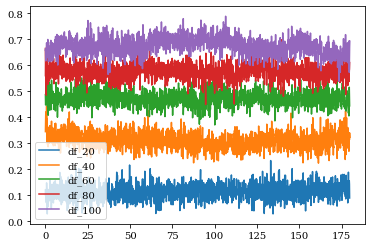

In [30]:
# plot magnitude wind speed from df_0 through df_100
# plt.plot(df_0['time'],df_0['magnitude_XY'],label='df_0')
plt.plot(df_20['time'],df_20['magnitude_XY'],label='df_20')
plt.plot(df_40['time'],df_40['magnitude_XY'],label='df_40')
plt.plot(df_60['time'],df_60['magnitude_XY'],label='df_60')
plt.plot(df_80['time'],df_80['magnitude_XY'],label='df_80')
plt.plot(df_100['time'],df_100['magnitude_XY'],label='df_100')
plt.legend()
plt.show()


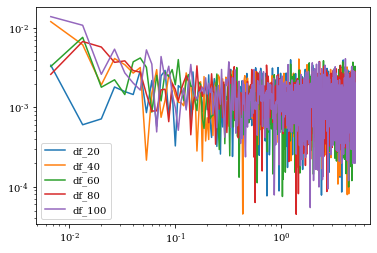

In [31]:
# plot the fft from df_0 through df_100
# plt.loglog(df_0['XY_FFT_X'],df_0['XY_FFT_Y'],label='df_0')
plt.loglog(df_20['XY_FFT_X'],df_20['XY_FFT_Y'],label='df_20')
plt.loglog(df_40['XY_FFT_X'],df_40['XY_FFT_Y'],label='df_40')
plt.loglog(df_60['XY_FFT_X'],df_60['XY_FFT_Y'],label='df_60')
plt.loglog(df_80['XY_FFT_X'],df_80['XY_FFT_Y'],label='df_80')
plt.loglog(df_100['XY_FFT_X'],df_100['XY_FFT_Y'],label='df_100')
plt.legend()
plt.show()

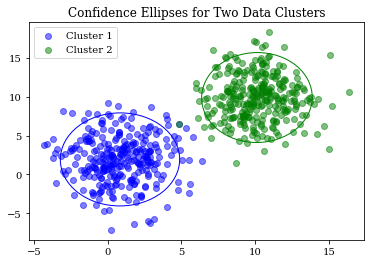

In [32]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def confidence_ellipse(x, y, ax, n_std=3.0, facecolor='none', **kwargs):
    """
    Create a plot of the covariance confidence ellipse of `x` and `y`
    """
    if x.size != y.size:
        raise ValueError("x and y must be the same size")
    cov = np.cov(x, y)
    pearson = cov[0, 1]/np.sqrt(cov[0, 0] * cov[1, 1])
    # Using a special case to obtain the eigenvalues of this
    # two-dimensional dataset.
    ell_radius_x = np.sqrt(1 + pearson)
    ell_radius_y = np.sqrt(1 - pearson)
    ellipse = Ellipse((0, 0), width=ell_radius_x * 2, height=ell_radius_y * 2, facecolor=facecolor, **kwargs)

    # Calculating the stdandard deviation of x from
    # the square root of the variance and multiplying
    # with the number of standard deviations.
    scale_x = np.sqrt(cov[0, 0]) * n_std
    mean_x = np.mean(x)

    # calculating the stdandard deviation of y ...
    scale_y = np.sqrt(cov[1, 1]) * n_std
    mean_y = np.mean(y)

    transf = transforms.Affine2D().rotate_deg(45).scale(scale_x, scale_y).translate(mean_x, mean_y)

    ellipse.set_transform(transf + ax.transData)
    return ax.add_patch(ellipse)

# Example data
np.random.seed(0)
data1 = np.random.randn(300, 2) * [2, 3] + [1, 2]
data2 = np.random.randn(300, 2) * [2, 3] + [10, 10]

fig, ax = plt.subplots()

ax.scatter(data1[:,0], data1[:,1], alpha=0.5, label='Cluster 1' ,color='blue')
ax.scatter(data2[:,0], data2[:,1], alpha=0.5, label='Cluster 2', color='green')

confidence_ellipse(data1[:,0], data1[:,1], ax, n_std=2, edgecolor='blue')
confidence_ellipse(data2[:,0], data2[:,1], ax, n_std=2, edgecolor='green')

ax.set_title('Confidence Ellipses for Two Data Clusters')
ax.legend()
plt.show()
